# Quickstart

This page splits the polarization image from [Tensors in plain words](tensors.ipynb) into
its five parts. Install pyBBTD first (see [Installation](installation.md)).

Load the data: 160 × 160 pixels, each with a Stokes vector of 4 numbers.

In [1]:
import numpy as np

from pybbtd import Stokes
from pybbtd.datasets import load_bbtd_board
from pybbtd.visualization import plot_stokes_terms

np.random.seed(0)
T = load_bbtd_board()

Create a model with **R = 5** terms whose spatial maps have rank **L = 25** (letters need
more complex shapes than simple blobs), and fit it to the data:

In [2]:
model = Stokes(T.shape[:2], R=5, L=25)
model.fit(
    T,
    init="kmeans",
    max_iter=5000,
    max_admm=2,
    rel_tol=1e-5,
    abs_tol=1e-7,
    admm_tol=1e-5,
)

Stokes(dims=(160, 160, 4), R=5, L=[25, 25, 25, 25, 25], block_mode='LL1')

The fitted factors are in `model.factors`. Plot each term: its spatial map on top, and the
polarization of its light below, drawn as the ellipse traced by the electric field
(a line for linear polarization, a circle for circular polarization):

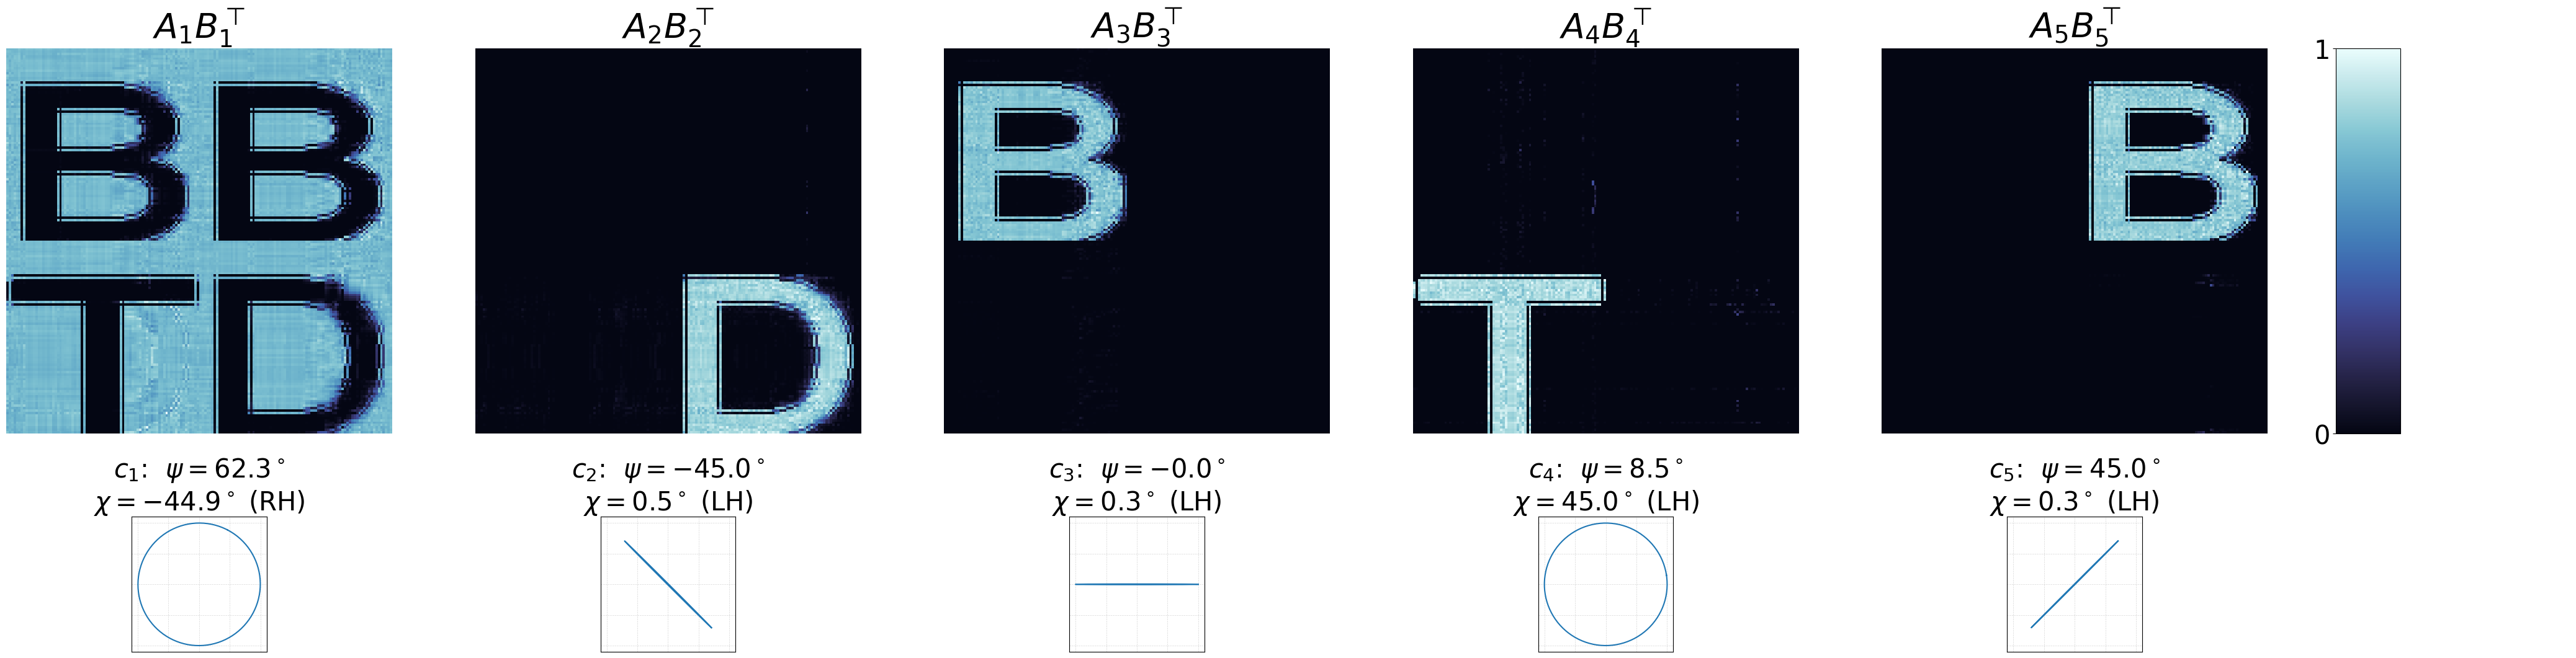

In [3]:
A, B, C = model.factors
plot_stokes_terms(A, B, C, R=5, L=25)

The five terms are the background and the letters B, B, T and D, each with its own
polarization. The order of the terms is arbitrary.

**Next:** the [BBTD board tutorial](../tutorials/stokes-bbtd-board.ipynb) looks at this
example in more detail, and [Choosing a model](../models/index.md) covers the other models.